In [3]:
!pip install pandas matplotlib wordcloud textblob scikit-learn

In [4]:
from google.colab import drive
import sys
import os
drive.mount('/content/gdrive')
drivePath = ('/content/gdrive/MyDrive/materi/data_Review_brawl_stars/')
sys.path.append(drivePath)
os.chdir(drivePath)
current_dir = os.getcwd()
current_dir

Mounted at /content/gdrive


'/content/gdrive/MyDrive/materi/data_Review_brawl_stars'

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from textblob import TextBlob
from collections import Counter
import seaborn as sns

# 1. LOAD DATA
df = pd.read_csv("brawlstars_reviews_sample.csv")

# Pastikan ada kolom 'content' (isi review) dan 'score' (rating)
print(df.head())

                               reviewId             userName  \
0  f1297d7b-ea87-47a3-ab6a-9fe7cd0e135b        Co co brawler   
1  a5edf012-9d9c-488e-9643-5ba85b866933     Anu Radha Sharma   
2  aebb218c-ccfd-49f8-8a7f-a5e9f70e2562             Pete Cro   
3  59b5b994-cc2b-45b5-8d7f-b67a7b10c7c7       Николай Ноткин   
4  d1cd97c1-6679-4b3d-8788-31224c919a01  christopher bullock   

                                           userImage  \
0  https://play-lh.googleusercontent.com/a-/ALV-U...   
1  https://play-lh.googleusercontent.com/a-/ALV-U...   
2  https://play-lh.googleusercontent.com/a-/ALV-U...   
3  https://play-lh.googleusercontent.com/a/ACg8oc...   
4  https://play-lh.googleusercontent.com/a/ACg8oc...   

                                             content  score  thumbsUpCount  \
0  There is no such thing as 'speech of freedom' ...      1              0   
1                                  best game love it      5              0   
2  The game keeps kicking me off rank match 

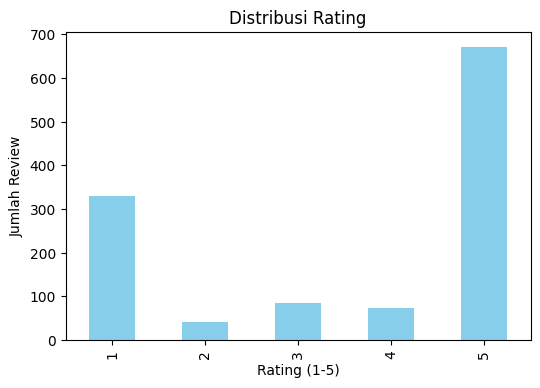

In [6]:
# 2. DISTRIBUSI RATING
plt.figure(figsize=(6,4))
df['score'].value_counts().sort_index().plot(kind='bar', color='skyblue')
plt.title("Distribusi Rating")
plt.xlabel("Rating (1-5)")
plt.ylabel("Jumlah Review")
plt.show()

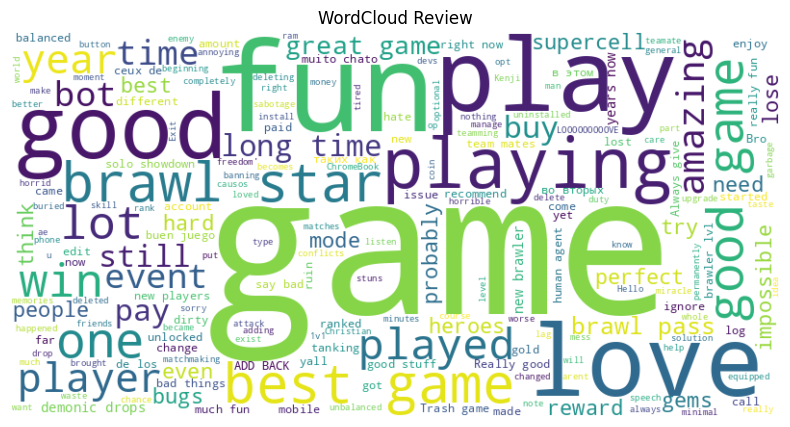

In [7]:
# 3. WORDCLOUD dari semua review
text = " ".join(str(review) for review in df['content'].dropna())
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud Review")
plt.show()


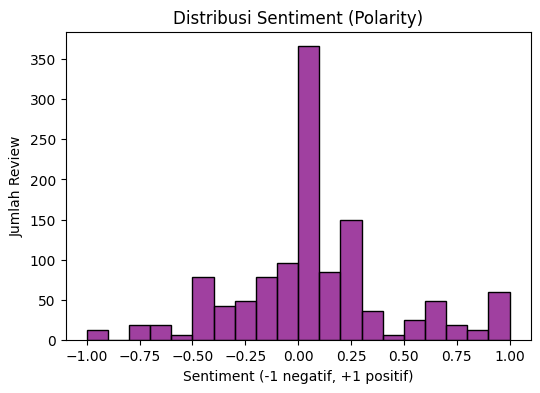

In [8]:
# 4. SENTIMENT ANALYSIS (sederhana dengan TextBlob)
def get_sentiment(text):
    try:
        return TextBlob(str(text)).sentiment.polarity
    except:
        return 0

df['sentiment'] = df['content'].apply(get_sentiment)

plt.figure(figsize=(6,4))
sns.histplot(df['sentiment'], bins=20, color="purple")
plt.title("Distribusi Sentiment (Polarity)")
plt.xlabel("Sentiment (-1 negatif, +1 positif)")
plt.ylabel("Jumlah Review")
plt.show()

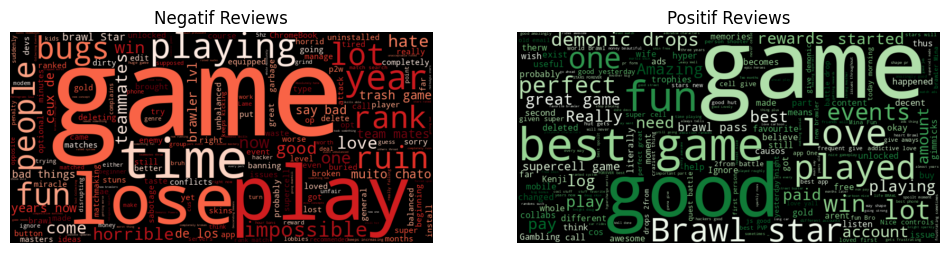

In [9]:
# 5. INSIGHT PRODUK (kata populer di review negatif vs positif)
neg_reviews = " ".join(df[df['sentiment'] < -0.1]['content'].dropna())
pos_reviews = " ".join(df[df['sentiment'] > 0.1]['content'].dropna())

neg_wc = WordCloud(width=800, height=400, background_color="black", colormap="Reds").generate(neg_reviews)
pos_wc = WordCloud(width=800, height=400, background_color="black", colormap="Greens").generate(pos_reviews)

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(neg_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Negatif Reviews")

plt.subplot(1,2,2)
plt.imshow(pos_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Positif Reviews")

plt.show()

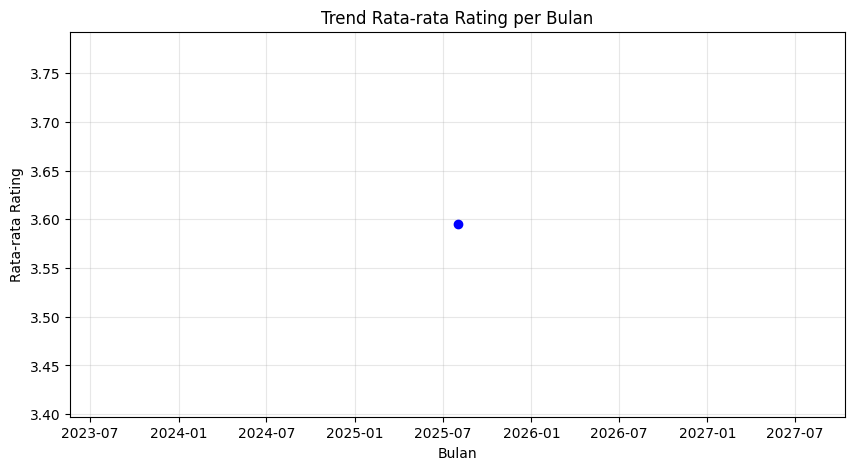

In [10]:
if 'at' in df.columns:
    df['at'] = pd.to_datetime(df['at'], errors="coerce")
    trend = df.groupby(df['at'].dt.to_period("M"))['score'].mean()
    trend.index = trend.index.to_timestamp()   # biar bisa jadi datetime

    plt.figure(figsize=(10,5))
    plt.plot(trend.index, trend.values, marker="o", color="blue")
    plt.title("Trend Rata-rata Rating per Bulan")
    plt.xlabel("Bulan")
    plt.ylabel("Rata-rata Rating")
    plt.grid(True, alpha=0.3)
    plt.show()


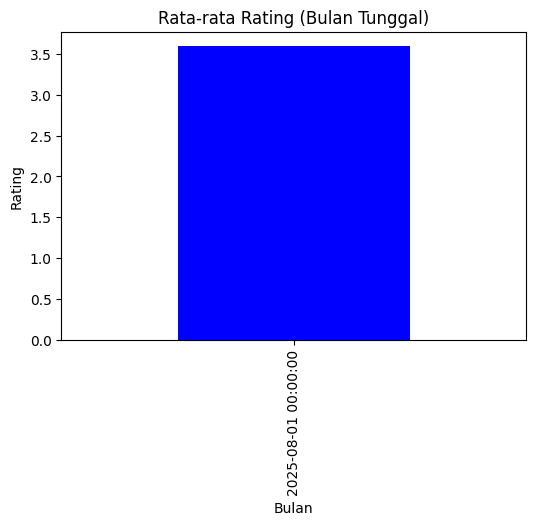

In [11]:
if len(trend) == 1:
    trend.plot(kind="bar", color="blue", figsize=(6,4))
    plt.title("Rata-rata Rating (Bulan Tunggal)")
    plt.xlabel("Bulan")
    plt.ylabel("Rating")
    plt.show()
else:
    trend.index = trend.index.to_timestamp()
    trend.plot(kind="line", marker="o", figsize=(10,5), color="blue")
    plt.title("Trend Rata-rata Rating per Bulan")
    plt.xlabel("Bulan")
    plt.ylabel("Rata-rata Rating")
    plt.show()


In [12]:
if "at" in df.columns:
    mean_rating = df.groupby(df["at"].dt.to_period("M"))["score"].mean()
    std = mean_rating.std()
    anomalies = mean_rating[(mean_rating - mean_rating.mean()).abs() > 1.5*std]

    print("📌 Bulan dengan rating anomali (drop/spike):")
    print(anomalies)

📌 Bulan dengan rating anomali (drop/spike):
Series([], Freq: M, Name: score, dtype: float64)
